<a href="https://colab.research.google.com/github/VictorTrasancos/Telco-Customer-Churn/blob/main/telco_customer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 0 - Bibliotecas

In [1]:
# Compilei aqui todas as bibliotecas utilizadas
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.inspection import permutation_importance


# Parte 1 - Preparação dos Dados

In [12]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Dimensões', df.shape)
display(df.head())

df.dtypes

# Valores ausentes, duplicados e inconsistências
print('TotalCharges em branco:', (df['TotalCharges'].astype(str).str.strip() == '').sum())
print('Valores ausentes por coluna:')
print(df.isna().sum()[lambda s: s > 0])
print('Duplicatas:', df.duplicated().sum(), '| customerID duplicados:', df['customerID'].duplicated().sum())

servicos_chk = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for c in servicos_chk:
    print(c, '- inconsistências com InternetService:',
          ((df['InternetService'] == 'No') != (df[c] == 'No internet service')).sum())
print('MultipleLines - inconsistências com PhoneService:',
      ((df['PhoneService'] == 'No') != (df['MultipleLines'] == 'No phone service')).sum())

# Clientes com tenure = 0 ainda não possuem valores a ser cobrado
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0

# Binarização de Churn e SeniorCitizen
df['y'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})

# CustomerID não tem valor preditivo, apenas confundiria o modelo
X = df.drop(columns=['customerID', 'Churn', 'y'])
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=42)
print(f"Dimensões do conjunto de Treino: {X_train.shape}")
print(f"Dimensões do conjunto de Teste: {X_test.shape}")

print(X_train.info())

Dimensões (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


TotalCharges em branco: 11
Valores ausentes por coluna:
Series([], dtype: int64)
Duplicatas: 0 | customerID duplicados: 0
OnlineSecurity - inconsistências com InternetService: 0
OnlineBackup - inconsistências com InternetService: 0
DeviceProtection - inconsistências com InternetService: 0
TechSupport - inconsistências com InternetService: 0
StreamingTV - inconsistências com InternetService: 0
StreamingMovies - inconsistências com InternetService: 0
MultipleLines - inconsistências com PhoneService: 0
Dimensões do conjunto de Treino: (5634, 19)
Dimensões do conjunto de Teste: (1409, 19)
<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   object 
 1   SeniorCitizen     5634 non-null   object 
 2   Partner           5634 non-null   object 
 3   Dependents        5634 non-null   object 
 4   tenure          

**Tipos das variáveis.** `TotalCharges` foi lida como texto (`object`) embora represente um valor monetário. O motivo é que 11 registros trazem uma string em branco (" ") nessa coluna. Convertemos com `pd.to_numeric(errors='coerce')`, o que transforma esses espaços em `NaN`. Ao inspecionar esses 11 casos, observamos que todos têm `tenure = 0`, ou seja, são clientes que acabaram de contratar o serviço e ainda não receberam nenhuma cobrança. Por isso o valor correto é `TotalCharges = 0`.

**Ausentes, duplicados e inconsistências.** Fora o caso de `TotalCharges`, não há valores ausentes nem duplicatas.

**Variáveis categóricas.** `SeniorCitizen` vinha como 0/1, mas é uma categoria (idoso ou não) e não uma quantidade. Por isso foi alterada para "Yes"/"No", igual às demais variáveis binárias.

**Exclusão de `customerID`.** O identificador é único para cada cliente, e cada valor aparece uma só vez.O modelo poderia sobreajustar caso `customerID`entrasse como preditor.

**Divisão treino/teste.** Dividimos os dados em 80% para treino e 20% para teste, de forma estratificada pela variável resposta, o que mantém a proporção de cancelamentos (≈26,5%) nos dois conjuntos. A divisão é feita antes de qualquer análise ou transformação, e o conjunto de teste só será usado na avaliação final.

# Parte 2 - Análise Exploratória

Proporção de cancelamento
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64
Medidas descritivas para as variáveis númericas por Churn


Churn                       0        1
tenure         count  4139.00  1495.00
               mean     37.59    18.36
               std      24.14    19.74
               min       0.00     1.00
               25%      15.00     2.00
               50%      38.00    10.00
               75%      61.00    29.00
               max      72.00    72.00
MonthlyCharges count  4139.00  1495.00
               mean     61.34    74.86
               std      31.14    24.60
               min      18.40    18.85
               25%      25.15    56.90
               50%      64.40    79.95
               75%      88.18    94.40
               max     118.75   118.35
TotalCharges   count  4139.00  1495.00
               mean   2564.72  1564.59
               std    2343.19  1908.84
               min       0.00    18.85
               25%     571.10   144.35
               50%    1686.15   740.30
               75%    4266.77  2368.73
               max    8672.45  8684.80

Proporção de cancelamento por Contract


,Tamanho_Grupo,Taxa_cancelamento_Perc
Contract,,
Month-to-month,3102,42.75
One year,1173,11.08
Two year,1359,2.87


Proporção de cancelamento por PaymentMethod


,Tamanho_Grupo,Taxa_cancelamento_Perc
PaymentMethod,,
Electronic check,1891,45.74
Mailed check,1286,19.28
Bank transfer (automatic),1244,16.16
Credit card (automatic),1213,14.92


... (7 outputs left out)

,Tamanho_Grupo,Taxa_cancelamento_Perc
StreamingTV,,
No,2226,33.11
Yes,2194,30.54
No internet service,1214,7.25


Proporção de cancelamento por PaperlessBilling


,Tamanho_Grupo,Taxa_cancelamento_Perc
PaperlessBilling,,
Yes,3331,33.80
No,2303,16.02


/tmp/ipykernel_3962/147568573.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_3962/147568573.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_3962/147568573.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
/tmp/ipykernel_3962/147568573.py:41: FutureWarning: 

Passing `palette` without a

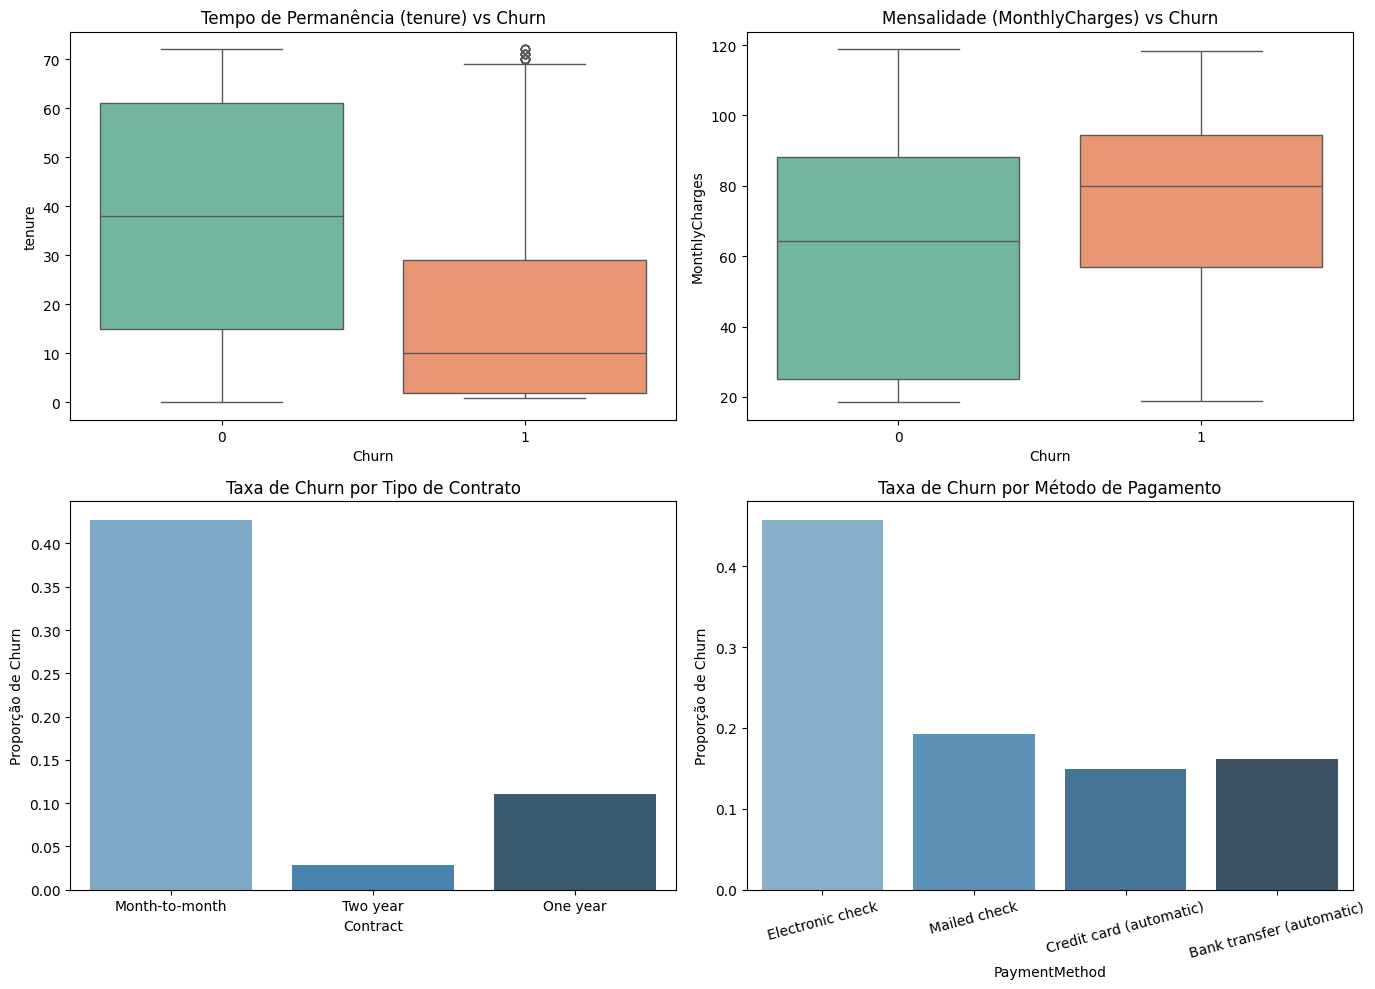

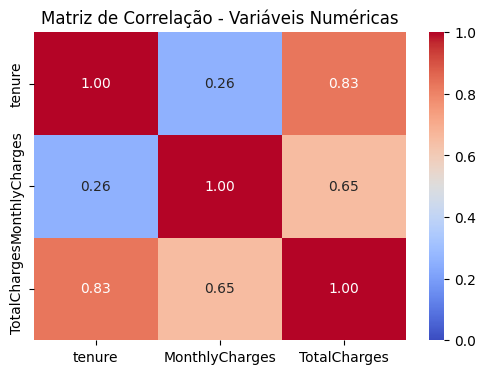

In [13]:
# Evitando vazamento de dados
tr = X_train.copy()
tr['Churn'] = y_train

# Proporção geral de cancelamento
print('Proporção de cancelamento')
print((tr['Churn'].value_counts(normalize = True)*100).round(2))

# Medidas descritivas para as variáveis númericas
num_cols = ['tenure','MonthlyCharges','TotalCharges']
print('Medidas descritivas para as variáveis númericas por Churn')
display(tr.groupby('Churn')[num_cols].describe().round(2).T)

# Grupos e Churn para variáveis categóricas
categ_cols = ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity', 'TechSupport', 'StreamingTV', 'PaperlessBilling']
for categ in categ_cols:
  resumo = tr.groupby(categ)['Churn'].agg(
      Tamanho_Grupo = 'size',
      Taxa_cancelamento_Perc ='mean'
  ).round(4)

  resumo['Taxa_cancelamento_Perc'] = resumo['Taxa_cancelamento_Perc']*100
  print(f'Proporção de cancelamento por {categ}')
  display(resumo.sort_values(by='Taxa_cancelamento_Perc', ascending = False))

# Plotagem
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Númericas vs Churn
sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Tempo de Permanência (tenure) vs Churn')

sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Mensalidade (MonthlyCharges) vs Churn')

# Categóricas vs Churn
sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title('Taxa de Churn por Tipo de Contrato')
axes[1, 0].set_ylabel('Proporção de Churn')

sns.barplot(data=tr, x='PaymentMethod', y='Churn', errorbar=None, ax=axes[1, 1], palette='Blues_d')
axes[1, 1].set_title('Taxa de Churn por Método de Pagamento')
axes[1, 1].set_ylabel('Proporção de Churn')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(tr[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Matriz de Correlação - Variáveis Numéricas')
plt.show()

Toda a análise exploratória usa apenas o conjunto de treino, para que nenhuma decisão posterior seja influenciada pelos dados de teste.

**Proporção de cancelamentos.** Cerca de 26,5% dos clientes cancelaram, então a base é desbalanceada. Isso tem uma consequência direta: um classificador que sempre responde "não cancela" teria cerca de 73,5% de acurácia sem identificar nenhum cancelamento. A acurácia, portanto, não é uma boa medida aqui, e usaremos precisão, sensibilidade, F1 e precisão média (Average Precision) da classe de cancelamento.

**Tempo de permanência (`tenure`).** Clientes que cancelam têm permanência bem menor: mediana de 10 meses contra 40 meses entre os que ficaram. O risco é maior nos primeiros meses e cai à medida que o cliente permanece na empresa.

**Valores cobrados.** A mensalidade (`MonthlyCharges`) é maior entre os que cancelam (média 80 contra 60). Já `TotalCharges` é menor entre os que cancelam, o que é um reflexo da permanência curta, já que o total acumulado cresce com o tempo de contrato.

**Tipo de contrato.** O contrato mensal concentra a maior taxa de cancelamento (45%), contra 10% no contrato de um ano e 2.5% no de dois anos.

**Forma de pagamento.** O cheque eletrônico (electronic check) apresenta a maior taxa de cancelamento (45%), enquanto os pagamentos automáticos (cartão e débito) têm as menores

**Serviços contratados.** Clientes com internet de fibra óptica cancelam mais do que os de DSL ou sem internet. Clientes sem `TechSupport` e sem `OnlineSecurity` cancelam mais do que os que têm esses serviços .

**Correlação entre variáveis numéricas.** O mapa de calor mostra correlação alta entre `tenure` e `TotalCharges` (0.83), o que é esperado, pois `TotalCharges` é aproximadamente `tenure × MonthlyCharges`. Isso indica redundância e será tratado na Parte 3.

# Parte 3 - Seleção e Transformação das Variáveis

In [14]:
# Seleção e Transformação de variáveis

def engenharia_atributos(d):
  d = d.copy()

  servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

  # Eliminando redundâncias
  for c in servicos:
    d[c] = d[c].replace({'No internet service': 'No'})
  d['MultipleLines'] = d['MultipleLines'].replace({'No phone service': 'No'})

  # Quantidade de serviços usados pelos clientes
  d['num_servicos_extras'] = (d[servicos] == 'Yes').sum(axis=1)

  # Houve aumento da mensalidade do cliente?
  d['ticket_medio'] = d['TotalCharges'] / d['tenure'].clip(lower=1)
  d['dif_preco'] = d['MonthlyCharges'] - d['ticket_medio']

  return d

X_train_eng = engenharia_atributos(X_train)
X_test_eng = engenharia_atributos(X_test)

# Removemos TotalCharges por sua redundância com tenure
num_cols = ['tenure', 'MonthlyCharges', 'num_servicos_extras', 'dif_preco']
cat_cols = X_train_eng.select_dtypes(include=['object']).columns.tolist()

# Aplicamos o StandarScaler para variáveis numéricas
# Aplicamos o OneHotEnconder para as categóricas, mas filtramos as que já são binárias para evitar duplicatas
preprocessor_eng = ColumnTransformer(transformers=[
    ('num',StandardScaler(),num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_teste = LogisticRegression(max_iter=1000, random_state=42)

# Analisando com os dados originais(incluindo total charges)
num_base = ['tenure', 'MonthlyCharges', 'TotalCharges']
preprocessor_base = ColumnTransformer([
    ('num', StandardScaler(), num_base),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])
pipe_base = Pipeline([('prep',preprocessor_base), ('clf',modelo_teste)])
score_base = cross_val_score(pipe_base, X_train, y_train, cv=cv, scoring='average_precision').mean()

# Analisando com os dados transformados
pipe_eng = Pipeline([('prep',preprocessor_eng), ('clf',modelo_teste)])
score_eng = cross_val_score(pipe_eng, X_train_eng, y_train, cv=cv, scoring='average_precision').mean()

print(f"Desempenho (Average Precision) - Base Original: {score_base:.4f}")
print(f"Desempenho (Average Precision) - Base Transformada: {score_eng:.4f}")

Desempenho (Average Precision) - Base Original: 0.6615
Desempenho (Average Precision) - Base Transformada: 0.6582


**Codificação.** As variáveis categóricas nominais não têm ordem natural, então usamos one-hot encoding. Codificar em números inteiros (1, 2, 3) criaria uma ordem inexistente, que modelos como a regressão logística e o KNN interpretariam como distância entre categorias.

A média e o desvio são calculados apenas nos dados de treino de cada rodada, porque a padronização está dentro do `Pipeline`. A regressão logística regularizada e o KNN dependem da escala das variáveis, e árvores e Random Forest não, por isso a necessidade de padronização.

1. As categorias "No internet service" e "No phone service" repetem a informação de `InternetService` e `PhoneService`. Foram unificadas em "No". Na base transformada essas categorias foram unificadas, mas, como optamos pela base original, os modelos finais mantêm as categorias originais; a coluna ‘No internet service’ repete a informação de InternetService = No;
2. `tenure` e `TotalCharges` são fortemente correlacionadas, como visto na Parte 2.

**Criação de variáveis.** Criamos três variáveis: `num_servicos_extras` (quantidade de serviços adicionais contratados), `ticket_medio` (`TotalCharges / tenure`) e `dif_preco` (diferença entre a mensalidade atual e o ticket médio histórico, indicando se houve aumento de preço). São transformações linha a linha, que não aprendem nada dos dados e, por isso, não geram vazamento.

**Resultado.** Comparamos, por validação cruzada com a regressão logística, a base original (AP = 0.66) com a base transformada (AP = 0.65). A transformação não melhorou o desempenho. Como o ganho não compensou a complexidade extra, seguimos com o conjunto mais simples (base original).


# Parte 4 - Construção dos modelos

In [15]:
# Métricas a serem calculdas na validação cruzada
SCORING = {
    'ap': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'precisao': 'precision',
    'sensibilidade': 'recall'
}

# Definindo dicionários e hiperparâmetros
modelos_grid = {
    "Regressão Logística": (
        LogisticRegression(max_iter=1000,random_state=42),
      {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_split": [2, 10, 20]}
    ),

    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [15, 31, 51], "clf__weights": ["uniform", "distance"]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"clf__max_depth": [5, 10], "clf__n_estimators": [100, 200]}
    )
}

# Laço de treinamento
resultados_lista = []
resultados_cv = {}

for nome, (modelo, grid) in modelos_grid.items():
  # Cria o pipeline com o processor obtido no bloco 3
  pipe = Pipeline([('prep',preprocessor_base), ('clf',modelo)])

  # Decide pelo Average Precision
  grid_search = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit='ap', n_jobs=-1)

  # Treinando o modelo
  grid_search.fit(X_train, y_train)

  # Armazena os resultados
  resultados_cv[nome] = grid_search

  # Obtendo as melhores métricas
  id_melhor = grid_search.best_index_
  linha = {"Modelo": nome}

  for m in SCORING:
        linha[m] = float(grid_search.cv_results_[f"mean_test_{m}"][id_melhor])

  linha['Melhores Parâmetros'] = str(grid_search.best_params_)
  resultados_lista.append(linha)

# Exibição em tabela
df_resultados = pd.DataFrame(resultados_lista)

# Ordenando pelas métricas para deixar o Average Precision (ap) em destaque
colunas_ordem = ['Modelo', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade', 'Melhores Parâmetros']
df_resultados = df_resultados[colunas_ordem].sort_values(by='ap', ascending=False).reset_index(drop=True)

display(df_resultados.round(4))

,Modelo,ap,roc_auc,f1,precisao,sensibilidade,Melhores Parâmetros
0,Regressão Logística,0.6615,0.8462,0.5932,0.6530,0.5445,{'clf__C': 1}
1,Random Forest,0.6571,0.8421,0.5772,0.6608,0.5130,"{'clf__max_depth': 10, 'clf__n_estimators': 200}"
2,KNN,0.6236,0.8358,0.5978,0.6214,0.5766,"{'clf__n_neighbors': 51, 'clf__weights': 'unif..."
3,Árvore de Decisão,0.6160,0.8293,0.5649,0.6345,0.5130,"{'clf__max_depth': 5, 'clf__min_samples_split'..."


Comparamos quatro classificadores diferentes:
- **Regressão logística:** modelo linear, simples e interpretável, usado como referência. Ajustamos `C`, o inverso da força da regularização (valores pequenos regularizam mais).
- **Árvore de decisão:** captura relações não lineares e interações, e é fácil de explicar. Tende a sobreajustar, então ajustamos `max_depth` e `min_samples_split` para controlar sua complexidade.
- **KNN:** classifica pelos vizinhos mais próximos, sem ajustar parâmetros. Ajustamos o número de vizinhos (`n_neighbors`) e o tipo de peso (`weights`). Depende da padronização feita no pipeline.
- **Random Forest:** conjunto de árvores treinadas em amostras diferentes, que reduz a variância de uma única árvore. Ajustamos `max_depth` e `n_estimators`.

**Protocolo.** Todos usam o mesmo pré-processador dentro de um `Pipeline` e a mesma validação cruzada estratificada com 5 dobras.Os hiperparâmetros são escolhidos pelo `GridSearchCV`.

**Resultados.** O melhor modelo na validação cruzada foi a `Regressão Logística` (AP = 0.6615	). Os modelos ficaram próximos entre si.

# Parte 5: Comparação dos métodos

In [16]:
# Coluna estratégia adicionada aos resultados do bloco 4
df_resultados['Estratégia'] = 'Original'

modelos_ponderados = {
    "Regressão Logística": (
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Árvore de Decisão": (
        DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_split": [2, 10, 20]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight='balanced', random_state=42),
        {"clf__max_depth": [5, 10], "clf__n_estimators": [100, 200]}
    )
}

# For para os modelos ponderados
resultados_ponderados = []

for nome, (modelo, grid) in modelos_ponderados.items():
    pipe = Pipeline([('prep', preprocessor_base), ('clf', modelo)])

    grid_search = GridSearchCV(pipe, grid, scoring=SCORING, refit='ap', cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)

    idx = grid_search.best_index_
    linha = {'Modelo': nome, 'Estratégia': 'Ponderado (class_weight)'}

    for m in SCORING:
        linha[m] = float(grid_search.cv_results_[f"mean_test_{m}"][idx])

    linha['Melhores Parâmetros'] = str(grid_search.best_params_)
    resultados_ponderados.append(linha)

# Unindo os resultados obtidos
df_ponderados = pd.DataFrame(resultados_ponderados)
df_final = pd.concat([df_resultados, df_ponderados], ignore_index=True)
df_final = df_final[['Modelo', 'Estratégia', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade', 'Melhores Parâmetros']]
tabela_cv = df_final.set_index(['Modelo', 'Estratégia']).sort_index()

print("Comparação de Métodos: Original vs Ponderado")
display(tabela_cv.round(4))

Comparação de Métodos: Original vs Ponderado


ap  roc_auc      f1  \
Modelo              Estratégia                                          
KNN                 Original                  0.6236   0.8358  0.5978   
Random Forest       Original                  0.6571   0.8421  0.5772   
                    Ponderado (class_weight)  0.6523   0.8433  0.6300   
Regressão Logística Original                  0.6615   0.8462  0.5932   
                    Ponderado (class_weight)  0.6600   0.8460  0.6293   
Árvore de Decisão   Original                  0.6160   0.8293  0.5649   
                    Ponderado (class_weight)  0.6140   0.8276  0.6152   

                                              precisao  sensibilidade  \
Modelo              Estratégia                                          
KNN                 Original                    0.6214         0.5766   
Random Forest       Original                    0.6608         0.5130   
                    Ponderado (class_weight)    0.5643         0.7137   
Regressão Logística Original                    0.6530         0.5445   
                    Ponderado (class_weight)    0.5178         0.8027   
Árvore de Decisão   Original                    0.6345         0.5130   
                    Ponderado (class_weight)    0.5097         0.7773   

                                                                            Melhores Parâmetros  
Modelo              Estratégia                                                                   
KNN                 Original                  {'clf__n_neighbors': 51, 'clf__weights': 'unif...  
Random Forest       Original                   {'clf__max_depth': 10, 'clf__n_estimators': 200}  
                    Ponderado (class_weight)   {'clf__max_depth': 10, 'clf__n_estimators': 200}  
Regressão Logística Original                                                      {'clf__C': 1}  
                    Ponderado (class_weight)                                      {'clf__C': 1}  
Árvore de Decisão   Original                  {'clf__max_depth': 5, 'clf__min_samples_split'...  
                    Ponderado (class_weight)  {'clf__max_depth': 5, 'clf__min_samples_split'...

Para comparar os métodos sob o mesmo protocolo, usamos os mesmos dados de treino, o mesmo pré-processador, a mesma validação cruzada e as mesmas métricas da Parte 4. Testamos a ponderação de classes (`class_weight='balanced'`), que atribui pesos inversamente proporcionais à frequência de cada classe.
Com a ponderação, a sensibilidade aumentou de 0.5445	 para 0.8027	 e a precisão diminuiu de 0.6530 para 0.5178, uma troca esperada, já que o modelo passa a classificar mais clientes como "cancela". A AP varia pouco porque ela mede a capacidade de ordenar os clientes por risco, e a ponderação muda principalmente as probabilidades e o ponto de corte, não essa ordenação. Concluímos que a ponderação ajuda a identificar mais cancelamentos, ao custo de mais falsos alarmes, e que o ganho em AP não é relevante.

# Parte 6 - Avaliação dos resultados

Modelo escolhido na validação cruzada: Regressão Logística
Desempenho no conjunto de teste (limiar 0,5, classe Churn = 1)


,precisao,sensibilidade,f1,roc_auc,ap
Modelo,,,,,
Random Forest,0.6490,0.5241,0.5799,0.8379,0.6548
Regressão Logística,0.6572,0.5588,0.6040,0.8420,0.6336
Árvore de Decisão,0.6347,0.5668,0.5989,0.8297,0.6218
KNN,0.5890,0.5749,0.5819,0.8285,0.6138


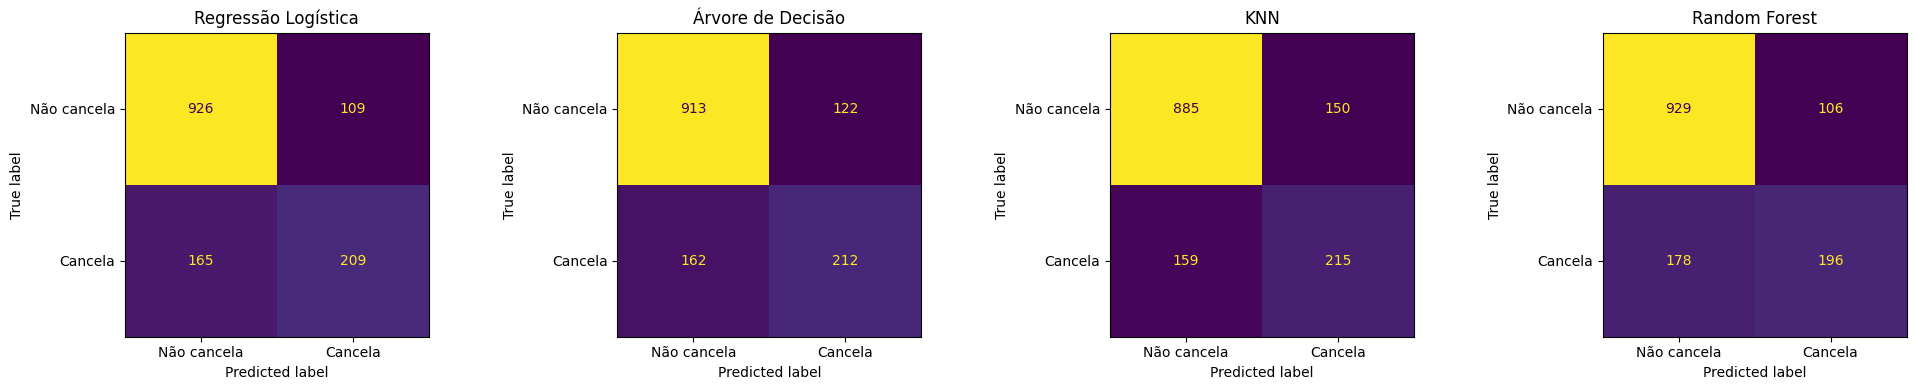

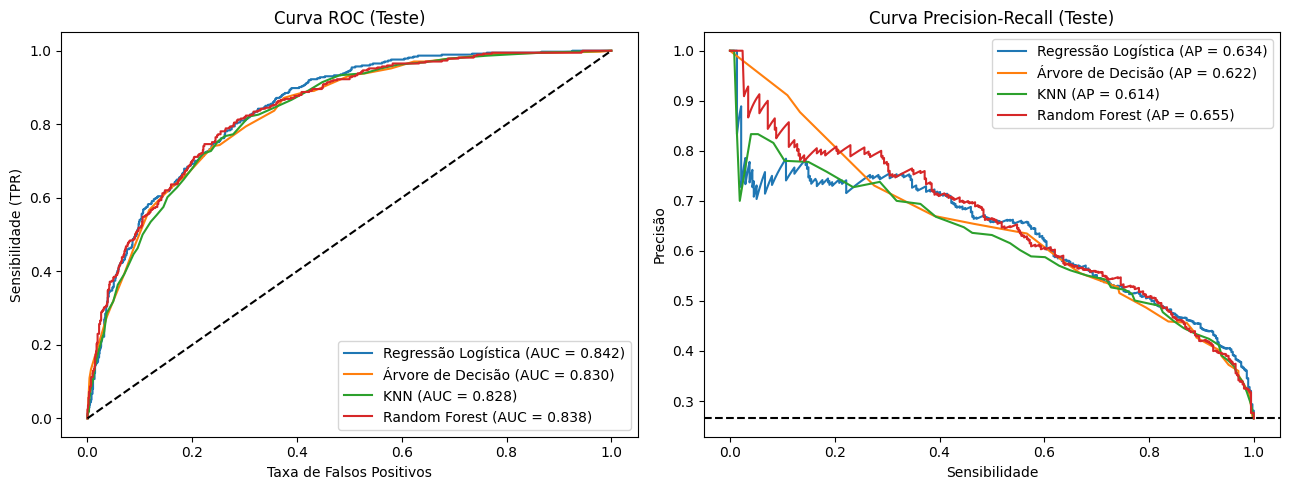


Contatando os 10% de clientes com maior risco


,Cancelamentos identificados (%),Precisão no grupo contatado (%),Lift sobre contato aleatório
Regressão Logística,28.34,75.18,2.83
Árvore de Decisão,27.54,73.05,2.75
KNN,27.81,73.76,2.78
Random Forest,29.41,78.01,2.94



Limiar padrão: 0.500 | Limiar ótimo (F1) calculado no treino: 0.328

Matriz de confusão com limiar 0.50 (padrão):
[[926 109]
 [165 209]]

Matriz de confusão com limiar 0.33 (ótimo no treino):
[[804 231]
 [104 270]]


,precisao,sensibilidade,f1
0.50 (padrão),0.6572,0.5588,0.6040
0.33 (ótimo no treino),0.5389,0.7219,0.6171


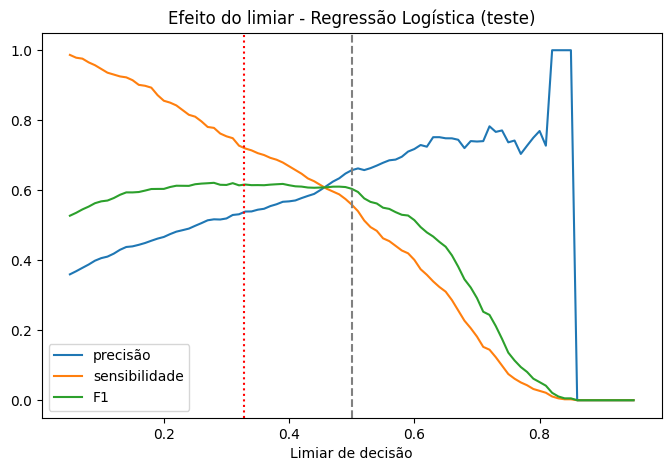

In [17]:
# O modelo final é escolhido pela validação cruzada (maior AP médio)
nome_melhor = df_resultados.loc[0, 'Modelo']
print(f'Modelo escolhido na validação cruzada: {nome_melhor}')

# Avaliação de todos os modelos no teste (limiar padrão 0,5)
linhas_teste = []
probas = {}
for nome, gs in resultados_cv.items():
    y_proba_m = gs.best_estimator_.predict_proba(X_test)[:, 1]
    y_pred_m = (y_proba_m >= 0.5).astype(int)
    probas[nome] = y_proba_m
    linhas_teste.append({
        'Modelo': nome,
        'precisao': precision_score(y_test, y_pred_m),
        'sensibilidade': recall_score(y_test, y_pred_m),
        'f1': f1_score(y_test, y_pred_m),
        'roc_auc': roc_auc_score(y_test, y_proba_m),
        'ap': average_precision_score(y_test, y_proba_m)
    })

df_teste = pd.DataFrame(linhas_teste).set_index('Modelo').sort_values('ap', ascending=False)
print('Desempenho no conjunto de teste (limiar 0,5, classe Churn = 1)')
display(df_teste.round(4))

# Matriz de confusão de cada modelo
fig, axes = plt.subplots(1, len(probas), figsize=(5 * len(probas), 4))
for ax, (nome, p_) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p_ >= 0.5).astype(int),
                                            display_labels=['Não cancela', 'Cancela'],
                                            colorbar=False, ax=ax)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

# Curvas ROC e Precision-Recall de todos os modelos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, p_ in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p_)
    axes[0].plot(fpr, tpr, label=f'{nome} (AUC = {roc_auc_score(y_test, p_):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, p_)
    axes[1].plot(rec, prec, label=f'{nome} (AP = {average_precision_score(y_test, p_):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('Curva ROC (Teste)')
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Sensibilidade (TPR)')
axes[0].legend()
axes[1].axhline(y_test.mean(), color='k', ls='--')
axes[1].set_title('Curva Precision-Recall (Teste)')
axes[1].set_xlabel('Sensibilidade')
axes[1].set_ylabel('Precisão')
axes[1].legend()
plt.tight_layout()
plt.show()

# Se a empresa contatar apenas 10% dos clientes, qual proporção dos cancelamentos seria identificada?
k = int(np.ceil(0.10 * len(y_test)))
linhas_top10 = {}
for nome, p_ in probas.items():
    idx = np.argsort(-p_)[:k]
    capturados = y_test.iloc[idx].sum()
    linhas_top10[nome] = {
        'Cancelamentos identificados (%)': 100 * capturados / y_test.sum(),
        'Precisão no grupo contatado (%)': 100 * capturados / k,
        'Lift sobre contato aleatório': (capturados / k) / y_test.mean()
    }
print('\nContatando os 10% de clientes com maior risco')
display(pd.DataFrame(linhas_top10).T.round(2))

# Efeito do limiar de decisão no modelo escolhido
modelo_escolhido = resultados_cv[nome_melhor].best_estimator_
y_proba = probas[nome_melhor]
oof_proba = cross_val_predict(modelo_escolhido, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * p * r / (p + r + 1e-12)
limiar_otimo = t[np.nanargmax(f1_scores[:-1])]
print(f'\nLimiar padrão: 0.500 | Limiar ótimo (F1) calculado no treino: {limiar_otimo:.3f}')

linhas_lim = {}
for nome_lim, lim in [('0.50 (padrão)', 0.5), (f'{limiar_otimo:.2f} (ótimo no treino)', limiar_otimo)]:
    y_pred_lim = (y_proba >= lim).astype(int)
    print(f'\nMatriz de confusão com limiar {nome_lim}:')
    print(confusion_matrix(y_test, y_pred_lim))
    linhas_lim[nome_lim] = {
        'precisao': precision_score(y_test, y_pred_lim),
        'sensibilidade': recall_score(y_test, y_pred_lim),
        'f1': f1_score(y_test, y_pred_lim)
    }
display(pd.DataFrame(linhas_lim).T.round(4))

# Como precisão, sensibilidade e F1 variam com o limiar (teste)
grade = np.linspace(0.05, 0.95, 91)
curva = pd.DataFrame({
    'precisão': [precision_score(y_test, (y_proba >= g).astype(int), zero_division=0) for g in grade],
    'sensibilidade': [recall_score(y_test, (y_proba >= g).astype(int)) for g in grade],
    'F1': [f1_score(y_test, (y_proba >= g).astype(int)) for g in grade]
}, index=grade)
curva.plot(figsize=(8, 5))
plt.axvline(0.5, color='gray', ls='--')
plt.axvline(limiar_otimo, color='red', ls=':')
plt.xlabel('Limiar de decisão')
plt.title(f'Efeito do limiar - {nome_melhor} (teste)')
plt.show()

**Comentário.** A Regressão Logística foi o modelo escolhido pela validação cruzada nos dados de treino (maior AP médio, 0.6615). O conjunto de teste (1.409 clientes, dos quais 374 cancelaram, ou 26,5%) manteve a distribuição original das classes e foi usado apenas nesta avaliação final.

**Modelo escolhido.** A Regressão Logística obteve a maior precisão (0,657), o maior F1 (0,604) e o maior ROC-AUC (0,842). O ROC-AUC pode ser lido como a probabilidade de um cliente que cancelou receber um escore de risco maior que o de um cliente que ficou: 84,2%. A AP foi de 0,634. Em bases desbalanceadas, a curva precisão-sensibilidade é mais informativa que a ROC, porque a taxa de falsos positivos fica diluída pelo grande número de clientes que não cancelam.

**Matriz de confusão (Regressão Logística, limiar 0,5).** O modelo acertou 209 cancelamentos (verdadeiros positivos) e 926 não cancelamentos (verdadeiros negativos). Errou de duas formas: deixou passar 165 clientes que cancelaram (falsos negativos, 44% dos cancelamentos) e sinalizou 109 clientes que ficaram (falsos positivos). Com o limiar padrão, o modelo é mais cuidadoso com os falsos alarmes (apenas 10,5% dos clientes que ficaram foram sinalizados) do que com os cancelamentos não detectados.

**A conclusão depende da métrica.** Os quatro modelos ficaram muito próximos (ROC-AUC entre 0,829 e 0,842), e o melhor muda conforme o critério. A Regressão Logística lidera em precisão, F1 e ROC-AUC. O KNN tem a maior sensibilidade (0,575), mas a menor precisão (0,589). A Random Forest tem a maior AP no teste (0,655 contra 0,634 da Regressão Logística) e também o melhor desempenho no top 10%. Mantemos a Regressão Logística: a escolha foi feita pela validação cruzada, e trocar de modelo depois de olhar o teste seria usar o teste para selecionar, o que anularia sua função de avaliação final. Além disso, com apenas 374 cancelamentos no teste, uma diferença de 0,02 na AP provavelmente está dentro da variação amostral, e as demais métricas favorecem a Regressão Logística. Como o desempenho é equivalente, o modelo linear, mais simples e interpretável, é preferível.

**Contato com 10% dos clientes.** Se a empresa contatar os 10% de clientes com maior risco previsto (141 clientes), o grupo da Regressão Logística contém 28,3% de todos os cancelamentos (106 dos 374), com precisão de 75,2% e lift de 2,83. Um contato aleatório identificaria apenas 10%.

Esse percentual tem um teto: com 141 contatos e 374 cancelamentos, o máximo possível seria 37,7%, então o limite da cobertura é o tamanho do grupo contatado, e não a qualidade da ordenação. A Random Forest (29,4%, lift 2,94) tem desempenho semelhante.

**Efeito do limiar de decisão.** O limiar 0,5 é conservador para uma classe minoritária. Escolhemos o limiar que maximiza o F1 usando as predições fora-da-dobra do treino (e não o teste, para não vazar informação), e obtivemos 0,328. No teste, a mudança de 0,50 para 0,33 produziu:

| Limiar | Precisão | Sensibilidade | F1 | Falsos negativos | Falsos positivos |
|---|---|---|---|---|---|
| 0,50 | 0,657 | 0,559 | 0,604 | 165 | 109 |
| 0,33 | 0,539 | 0,722 | 0,617 | 104 | 231 |

A sensibilidade subiu 16 pontos percentuais e a precisão caiu 12. O F1 subiu pouco (de 0,604 para 0,617), mas a composição dos erros mudou bastante: 61 cancelamentos a mais foram detectados, ao custo de 122 falsos alarmes a mais, ou seja, cada cancelamento adicional detectado custa cerca de dois contatos desnecessários. O limiar não altera a ordenação dos clientes por risco, então ROC-AUC e AP permanecem iguais; ele apenas move o equilíbrio entre os dois tipos de erro. A escolha final depende de custos que a base não traz: se a ação de retenção for barata em relação ao valor de um cliente perdido, compensa usar o limiar menor e aceitar mais falsos alarmes; se for cara, o limiar de 0,5 é mais adequado.

# Parte 7 - Análise de estratégias de balanceamento

ok: Undersampling (RUS)
ok: Oversampling (ROS)
ok: Oversampling (SMOTE)
Validação cruzada (treino) - todas as estratégias


ap  roc_auc      f1  \
Modelo              Estratégia                                          
KNN                 Original                  0.6236   0.8358  0.5978   
                    Oversampling (ROS)        0.6100   0.8306  0.6050   
                    Oversampling (SMOTE)      0.6079   0.8330  0.6018   
                    Undersampling (RUS)       0.6241   0.8351  0.6044   
Random Forest       Original                  0.6571   0.8421  0.5772   
                    Oversampling (ROS)        0.6514   0.8403  0.6305   
                    Oversampling (SMOTE)      0.6457   0.8418  0.6341   
                    Ponderado (class_weight)  0.6523   0.8433  0.6300   
                    Undersampling (RUS)       0.6518   0.8454  0.6234   
Regressão Logística Original                  0.6615   0.8462  0.5932   
                    Oversampling (ROS)        0.6586   0.8458  0.6278   
                    Oversampling (SMOTE)      0.6587   0.8449  0.6332   
                    Ponderado (class_weight)  0.6600   0.8460  0.6293   
                    Undersampling (RUS)       0.6616   0.8463  0.6268   
Árvore de Decisão   Original                  0.6160   0.8293  0.5649   
                    Oversampling (ROS)        0.6093   0.8272  0.6151   
                    Oversampling (SMOTE)      0.5744   0.8213  0.6134   
                    Ponderado (class_weight)  0.6140   0.8276  0.6152   
                    Undersampling (RUS)       0.5880   0.8234  0.6063   

                                              precisao  sensibilidade  
Modelo              Estratégia                                         
KNN                 Original                    0.6214         0.5766  
                    Oversampling (ROS)          0.4760         0.8308  
                    Oversampling (SMOTE)        0.4646         0.8548  
                    Undersampling (RUS)         0.4694         0.8488  
Random Forest       Original                    0.6608         0.5130  
                    Oversampling (ROS)          0.5503         0.7385  
                    Oversampling (SMOTE)        0.5755         0.7064  
                    Ponderado (class_weight)    0.5643         0.7137  
                    Undersampling (RUS)         0.5026         0.8214  
Regressão Logística Original                    0.6530         0.5445  
                    Oversampling (ROS)          0.5161         0.8020  
                    Oversampling (SMOTE)        0.5290         0.7893  
                    Ponderado (class_weight)    0.5178         0.8027  
                    Undersampling (RUS)         0.5146         0.8020  
Árvore de Decisão   Original                    0.6345         0.5130  
                    Oversampling (ROS)          0.5085         0.7806  
                    Oversampling (SMOTE)        0.5184         0.7518  
                    Ponderado (class_weight)    0.5097         0.7773  
                    Undersampling (RUS)         0.4964         0.7833


Teste (limiar 0,5, classe Churn = 1)


,,precisao,sensibilidade,f1,ap,roc_auc
Modelo,Estratégia,,,,,
Regressão Logística,Original,0.6572,0.5588,0.6040,0.6336,0.8420
Árvore de Decisão,Original,0.6347,0.5668,0.5989,0.6218,0.8297
KNN,Original,0.5890,0.5749,0.5819,0.6138,0.8285
Random Forest,Original,0.6490,0.5241,0.5799,0.6548,0.8379
Regressão Logística,Undersampling (RUS),0.5095,0.7861,0.6183,0.6337,0.8427
Árvore de Decisão,Undersampling (RUS),0.5142,0.7246,0.6016,0.6144,0.8268
KNN,Undersampling (RUS),0.4755,0.8289,0.6043,0.6172,0.8305
Random Forest,Undersampling (RUS),0.5070,0.7781,0.6139,0.6444,0.8402
Regressão Logística,Oversampling (ROS),0.4983,0.7861,0.6100,0.6319,0.8421



Variação em relação ao Original (positivo = melhorou)

precisao


Estratégia,Undersampling (RUS),Oversampling (ROS),Oversampling (SMOTE)
Modelo,,,
KNN,-0.1136,-0.1098,-0.1298
Random Forest,-0.1420,-0.1129,-0.0984
Regressão Logística,-0.1477,-0.1589,-0.1538
Árvore de Decisão,-0.1205,-0.1273,-0.1257


... (2 outputs left out)


f1


Estratégia,Undersampling (RUS),Oversampling (ROS),Oversampling (SMOTE)
Modelo,,,
KNN,0.0224,0.0269,0.0203
Random Forest,0.0340,0.0402,0.0357
Regressão Logística,0.0143,0.0059,0.0097
Árvore de Decisão,0.0027,0.0275,-0.0170



ap


Estratégia,Undersampling (RUS),Oversampling (ROS),Oversampling (SMOTE)
Modelo,,,
KNN,0.0034,-0.0035,-0.0057
Random Forest,-0.0103,-0.0050,-0.0192
Regressão Logística,0.0001,-0.0017,-0.0054
Árvore de Decisão,-0.0074,-0.0035,-0.0749


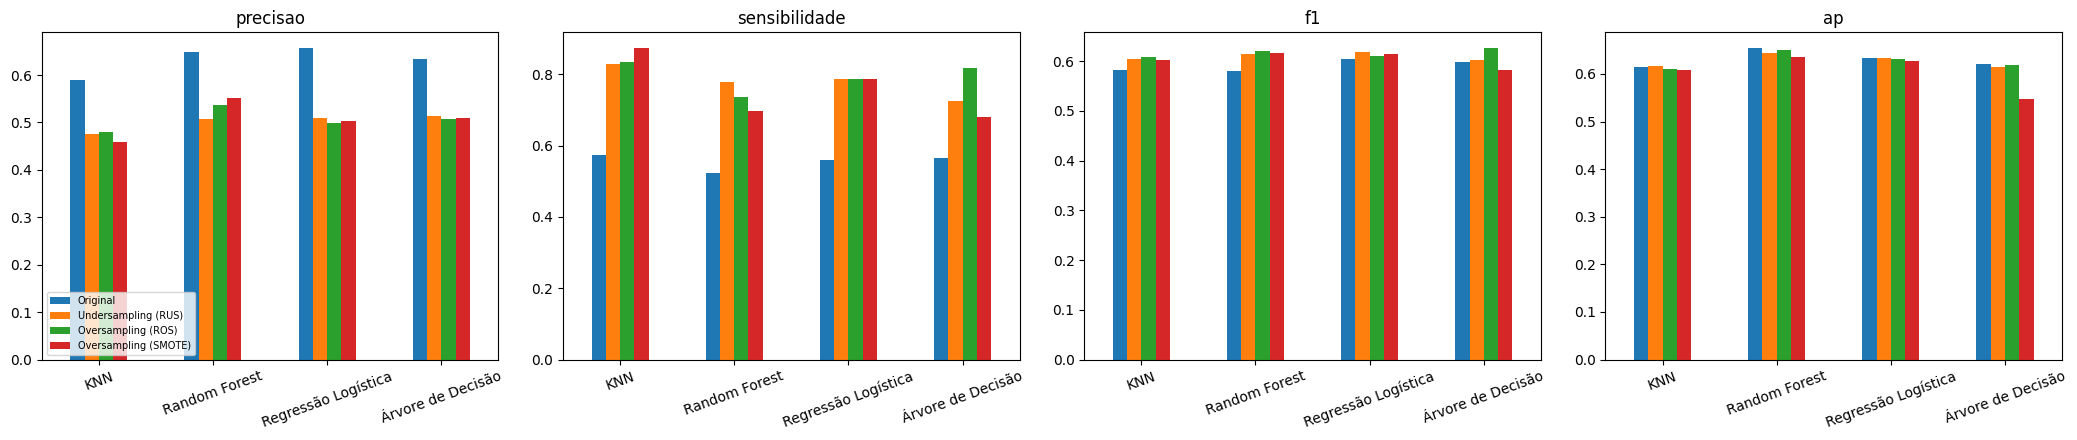

In [18]:
# Mesmos 4 algoritmos, mesmos grids, mesmo preprocessor e mesma validação cruzada da Parte 4.
# A reamostragem é um passo do ImbPipeline: só atua nos dados de treino de cada dobra.
amostradores = {
    "Undersampling (RUS)": RandomUnderSampler(random_state=42),
    "Oversampling (ROS)": RandomOverSampler(random_state=42),
    "Oversampling (SMOTE)": SMOTE(random_state=42)
}

resultados_bal = {}
linhas_bal = []

for estrategia, sampler in amostradores.items():
    for nome, (modelo, grid) in modelos_grid.items():
        pipe_imb = ImbPipeline([
            ('prep', preprocessor_base),
            ('sampler', sampler),
            ('clf', modelo)
        ])
        gs = GridSearchCV(pipe_imb, grid, scoring=SCORING, refit='ap', cv=cv, n_jobs=-1)
        gs.fit(X_train, y_train)
        resultados_bal[(nome, estrategia)] = gs

        idx = gs.best_index_
        linha = {'Modelo': nome, 'Estratégia': estrategia}
        for m in SCORING:
            linha[m] = float(gs.cv_results_[f"mean_test_{m}"][idx])
        linha['Melhores Parâmetros'] = str(gs.best_params_)
        linhas_bal.append(linha)
    print('ok:', estrategia)

# Tabela de validação cruzada: Original + Ponderado (Parte 5) + reamostragens
df_bal = pd.DataFrame(linhas_bal)
comparativo = pd.concat([df_final, df_bal], ignore_index=True)
comparativo = comparativo[['Modelo', 'Estratégia', 'ap', 'roc_auc', 'f1', 'precisao', 'sensibilidade']]
print('Validação cruzada (treino) - todas as estratégias')
display(comparativo.set_index(['Modelo', 'Estratégia']).sort_index().round(4))

# Avaliação final no teste (limiar 0,5): Original vs reamostragens
estrategias_teste = {}
for nome, gs in resultados_cv.items():
    estrategias_teste[(nome, 'Original')] = gs
estrategias_teste.update(resultados_bal)

linhas_t = []
for (nome, estrategia), gs in estrategias_teste.items():
    y_proba_b = gs.best_estimator_.predict_proba(X_test)[:, 1]
    y_pred_b = (y_proba_b >= 0.5).astype(int)
    linhas_t.append({
        'Modelo': nome, 'Estratégia': estrategia,
        'precisao': precision_score(y_test, y_pred_b),
        'sensibilidade': recall_score(y_test, y_pred_b),
        'f1': f1_score(y_test, y_pred_b),
        'ap': average_precision_score(y_test, y_proba_b),
        'roc_auc': roc_auc_score(y_test, y_proba_b)
    })
tabela_teste = pd.DataFrame(linhas_t).set_index(['Modelo', 'Estratégia'])
ordem = ['Original'] + list(amostradores)
print('\nTeste (limiar 0,5, classe Churn = 1)')
display(tabela_teste.round(4))

# Variação em relação ao treinamento com a distribuição original (teste)
print('\nVariação em relação ao Original (positivo = melhorou)')
for m in ['precisao', 'sensibilidade', 'f1', 'ap']:
    tab_m = tabela_teste[m].unstack('Estratégia')[ordem]
    print(f'\n{m}')
    display(tab_m.sub(tab_m['Original'], axis=0).drop(columns='Original').round(4))

# Gráfico
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, m in zip(axes, ['precisao', 'sensibilidade', 'f1', 'ap']):
    tabela_teste[m].unstack('Estratégia')[ordem].plot(kind='bar', ax=ax, legend=False)
    ax.set_title(m)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
axes[0].legend(fontsize=7, loc='lower left')
plt.tight_layout()
plt.show()

**Undersampling aleatório (RUS).** Remove clientes da classe majoritária até igualar as classes. No treino, isso descarta cerca de 64% dos clientes que não cancelaram (ou cerca de 47% de todas as linhas).

**Oversampling aleatório (ROS).** Duplica clientes da classe minoritária até igualar as classes (cada cliente que cancelou é repetido em média 2,8 vezes).

**SMOTE.** Cria exemplos sintéticos da classe minoritária por interpolação entre vizinhos próximos, em vez de copiá-los.

**Resultados.** A reamostragem ajuda quando o objetivo é capturar mais cancelamentos (sensibilidade), mas não melhora de forma consistente a AP.

# Parte 8 - Interpretação e discussão crítica

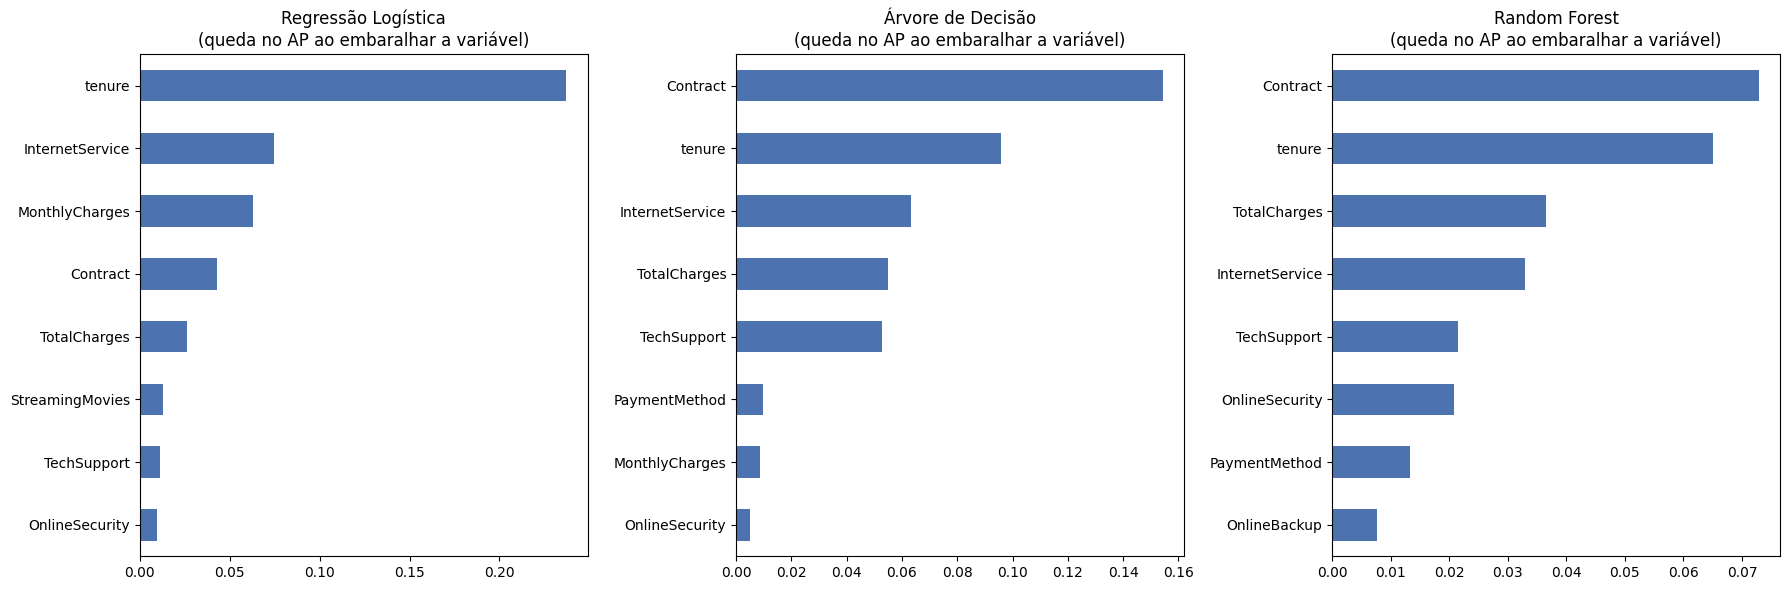

Ranking de importância por modelo


,Regressão Logística,Árvore de Decisão,Random Forest,posição média
tenure,1,2,2,1.666667
Contract,4,1,1,2.000000
InternetService,2,3,4,3.000000
TotalCharges,5,4,3,4.000000
TechSupport,7,5,5,5.666667
MonthlyCharges,3,7,10,6.666667
OnlineSecurity,8,8,6,7.333333
PaymentMethod,10,6,7,7.666667
OnlineBackup,13,10,8,10.333333
StreamingMovies,6,15,11,10.666667


Correlação de Spearman entre as importâncias dos modelos


,Regressão Logística,Árvore de Decisão,Random Forest
Regressão Logística,1.00,0.74,0.67
Árvore de Decisão,0.74,1.00,0.88
Random Forest,0.67,0.88,1.00



Reduzem o risco de cancelamento (razão de chances < 1)
num__tenure                                0.288
cat__Contract_Two year                     0.442
cat__InternetService_DSL                   0.496
num__MonthlyCharges                        0.549
cat__OnlineSecurity_No internet service    0.705
dtype: float64

Aumentam o risco de cancelamento (razão de chances > 1)
cat__PaymentMethod_Electronic check    1.176
cat__PaperlessBilling_Yes              1.448
num__TotalCharges                      1.682
cat__Contract_Month-to-month           1.698
cat__InternetService_Fiber optic       1.811
dtype: float64

Priorização de ações de retenção - Regressão Logística


,Volume_Clientes,Cancelamentos_Capturados,Taxa_Cancelamento_No_Grupo,Recall_Acumulado (%)
Decil,,,,
1,141,106,0.752,28.3
2,141,80,0.567,49.7
3,141,57,0.404,65.0
4,141,49,0.348,78.1
5,140,34,0.243,87.2
6,141,23,0.163,93.3
7,141,16,0.113,97.6
8,141,5,0.035,98.9
9,141,2,0.014,99.5


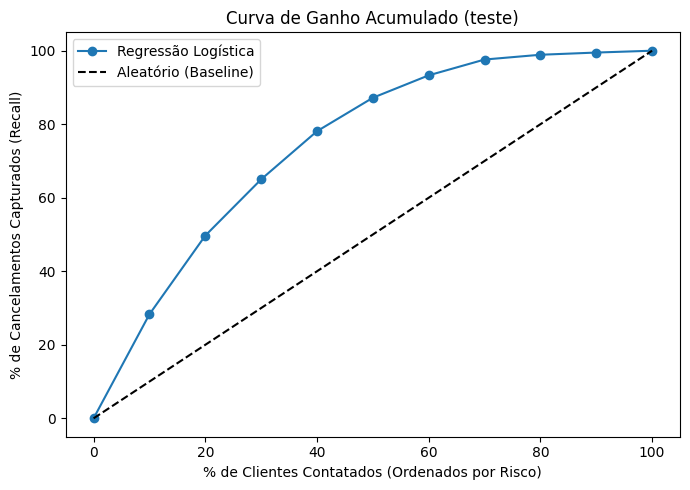

In [19]:
# 1) Importância por permutação em três modelos (queda no AP ao embaralhar cada variável original, no teste)
modelos_interp = ['Regressão Logística', 'Árvore de Decisão', 'Random Forest']
imp = {}
for nome in modelos_interp:
    r_ = permutation_importance(resultados_cv[nome].best_estimator_, X_test, y_test,
                                scoring='average_precision', n_repeats=10,
                                random_state=42, n_jobs=-1)
    imp[nome] = pd.Series(r_.importances_mean, index=X_test.columns)
imp = pd.DataFrame(imp)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, nome in zip(axes, modelos_interp):
    imp[nome].sort_values().tail(8).plot(kind='barh', ax=ax, color='#4C72B0')
    ax.set_title(f'{nome}\n(queda no AP ao embaralhar a variável)')
plt.tight_layout()
plt.show()

# Consistência entre modelos: posição de cada variável no ranking (1 = mais importante)
ranking = imp.rank(ascending=False).astype(int)
ranking['posição média'] = ranking.mean(axis=1)
print('Ranking de importância por modelo')
display(ranking.sort_values('posição média').head(10))

print('Correlação de Spearman entre as importâncias dos modelos')
display(imp.corr(method='spearman').round(2))

# 2) Como cada categoria afeta o risco (Regressão Logística)
modelo_lr = resultados_cv['Regressão Logística'].best_estimator_
nomes_features = modelo_lr.named_steps['prep'].get_feature_names_out()
coeficientes = modelo_lr.named_steps['clf'].coef_[0]

# exp(coeficiente) = razão de chances (para as numéricas: efeito de +1 desvio-padrão)
razoes = pd.Series(np.exp(coeficientes), index=nomes_features).sort_values()

print('\nReduzem o risco de cancelamento (razão de chances < 1)')
print(razoes.head(5).round(3))
print('\nAumentam o risco de cancelamento (razão de chances > 1)')
print(razoes.tail(5).round(3))

# 3) Priorização de ações: ganho acumulado por decil de risco (modelo escolhido na Parte 6)
proba_teste = probas[nome_melhor]
tab = pd.DataFrame({'Churn_Real': y_test.values, 'Probabilidade': proba_teste})

# Decil 1 = maior risco de cancelamento
tab['Decil'] = 10 - pd.qcut(tab['Probabilidade'].rank(method='first'), 10, labels=False)

ganho = tab.groupby('Decil')['Churn_Real'].agg(
    Volume_Clientes='size',
    Cancelamentos_Capturados='sum'
)
ganho['Taxa_Cancelamento_No_Grupo'] = (ganho['Cancelamentos_Capturados'] / ganho['Volume_Clientes']).round(3)
ganho['Recall_Acumulado (%)'] = (ganho['Cancelamentos_Capturados'].cumsum()
                                 / ganho['Cancelamentos_Capturados'].sum() * 100).round(1)

print(f'\nPriorização de ações de retenção - {nome_melhor}')
display(ganho)

plt.figure(figsize=(7, 5))
plt.plot(np.insert(ganho.index.values * 10, 0, 0),
         np.insert(ganho['Recall_Acumulado (%)'].values, 0, 0),
         marker='o', label=nome_melhor)
plt.plot([0, 100], [0, 100], 'k--', label='Aleatório (Baseline)')
plt.title('Curva de Ganho Acumulado (teste)')
plt.xlabel('% de Clientes Contatados (Ordenados por Risco)')
plt.ylabel('% de Cancelamentos Capturados (Recall)')
plt.legend()
plt.tight_layout()
plt.show()

O tempo de permanência (`tenure`) e o tipo de contrato (`Contract`) são as variáveis mais relevantes, seguidas pelo tipo de internet (`InternetService`) e pelo valor total pago (`TotalCharges`). Em seguida aparecem `TechSupport`, `OnlineSecurity` e `PaymentMethod`. Isso é coerente com a análise exploratória (Parte 2).

**Consistência entre os modelos.** A correlação de Spearman entre as importâncias foi de 0,74 (regressão logística e árvore), 0,67 (regressão logística e Random Forest) e 0,88 (árvore e Random Forest).

Os resultados que são coerentes com a exploração: a fibra óptica, o contrato mensal e o pagamento por cheque eletrônico aumentam o risco, enquanto o contrato de dois anos, o DSL e maior permanência o reduzem.

O 1º decil tem taxa de cancelamento de 75,2%, quase 2,8 vezes a taxa média do teste (26,5%). Contatar os 30% de clientes de maior risco captura 65% dos cancelamentos, e os 40% de maior risco capturam 78%. Os três últimos decis (30% dos clientes) concentram apenas 2,4% dos cancelamentos (9 de 374). O modelo, portanto, separa bem os clientes de alto risco dos de baixo risco, o que permite concentrar a ação de retenção em uma fração da base.

**Possíveis aplicações em retenção.** Os resultados sugerem hipóteses a testar, e não ações comprovadas:
- incentivar a migração de clientes de contrato mensal para contratos anuais ou de dois anos (descontos, benefícios);
- oferecer suporte técnico e segurança online a clientes que não os têm, pois `TechSupport` e `OnlineSecurity` aparecem entre as variáveis relevantes nos três modelos;
- incentivar o pagamento automático para clientes que pagam por cheque eletrônico;
- dar atenção especial aos primeiros meses de relacionamento, quando o risco é maior;
- investigar a qualidade e o preço da fibra óptica, que tem a maior razão de chances.

**Limitações.**
- Os dados são observacionais e de um único momento, sem datas dos eventos, então não é possível validar o modelo ao longo do tempo.
- O cancelamento refere-se apenas ao último mês.
- Não há informação sobre o custo das ações nem sobre o valor de cada cliente, necessários para escolher o limiar e o número de clientes a contatar.
- O teste tem apenas 374 cancelamentos, e as métricas e os rankings de importância foram obtidos em uma única divisão. Não medimos a incerteza (por exemplo, com intervalos de confiança por bootstrap), então diferenças pequenas entre modelos não devem ser consideradas relevantes.
- Os dados vêm de uma única empresa e podem não se generalizar.
- Como as variáveis são correlacionadas, a importância e os coeficientes individuais são menos confiáveis.

**Associação versus causalidade.** O modelo mostra quais características estão associadas ao cancelamento, não o que o causa. Clientes com contrato de dois anos cancelam menos, mas isso pode refletir o fato de que clientes mais fiéis escolhem contratos longos, e não que o contrato reduza o cancelamento. Também pode haver causalidade reversa (quem pretende sair evita contratos longos) e fatores não observados, como satisfação, qualidade do serviço e ofertas da concorrência. Como não houve intervenção nem grupo de controle, os dados não permitem concluir que as ações de retenção reduziriam os cancelamentos. Além disso, o cliente de maior risco previsto não é necessariamente o mais sensível à ação.

## Respostas

**Quais características estão associadas a maiores taxas de cancelamento?** Contrato mensal, permanência curta, internet de fibra óptica, pagamento por cheque eletrônico e ausência de suporte técnico e segurança online.

**Como permanência, contrato e valores cobrados se relacionam com o cancelamento?** O risco cai com a permanência e com contratos mais longos. Quem cancela paga, em média, mensalidades maiores e acumula menos `TotalCharges`, por ter permanecido menos tempo. Na regressão, em que as variáveis são consideradas em conjunto, os sinais de `MonthlyCharges` e `TotalCharges` se invertem por causa da colinearidade, e só devem ser interpretados junto com `tenure` e os serviços contratados.

**Qual classificador apresenta os melhores resultados? A conclusão depende da métrica?** A Regressão Logística foi escolhida pela validação cruzada (AP = 0,6615) e, no teste, teve a maior precisão (0,657), o maior F1 (0,604) e o maior ROC-AUC (0,842). A Random Forest teve a maior AP no teste (0,655) e o KNN, a maior sensibilidade (0,575). Sim, a conclusão depende da métrica, mas as diferenças são pequenas, e o modelo linear, mais simples e interpretável, é competitivo.

**O tratamento do desbalanceamento melhora o desempenho?** A ponderação de classes e o ajuste do limiar aumentam a sensibilidade ao custo da precisão e pouco alteram a AP: com o limiar de 0,33, por exemplo, a sensibilidade da Regressão Logística subiu de 0,559 para 0,722, e a precisão caiu de 0,657 para 0,539.

**Se a empresa pudesse contatar apenas 10% dos clientes, qual proporção dos cancelamentos seria identificada?** Cerca de 28,3% (106 dos 374 cancelamentos), com precisão de 75,2% no grupo contatado e lift de 2,83. O máximo possível com esse número de contatos seria 37,7%.

**Quais resultados poderiam orientar hipóteses para ações de retenção? Por que os dados não permitem concluir que essas ações reduziriam os cancelamentos?** Os resultados sugerem priorizar clientes de contrato mensal, nos primeiros meses de relacionamento, com fibra óptica, pagamento por cheque eletrônico e sem suporte técnico ou segurança online. Os dados, porém, são observacionais, sem intervenção nem grupo de controle, e as associações podem refletir fatores não observados ou causalidade reversa. Para avaliar o efeito de uma ação seria necessário um experimento controlado.